In [1]:
import boto3
import torch
import io
import re
from typing import List, Tuple
import yaml
from omegaconf import OmegaConf
from dinov3.inferance import load_teacher_model_for_inference, make_inference_dataset, make_inference_dataloader

W0323 11:04:00.000000 18857 site-packages/torch/distributed/elastic/multiprocessing/redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


In [ ]:
def get_checkpoint(bucket_name, base_prefix = "", iteration = None) -> str:
    """
    Get checkpoint from aws, optionally select iter, which should be
    in multiples of 1000-1, ie 999, 1999, ...

    If iteration = None, latest is selected
    """
    s3_client = boto3.client("s3")
    paginator = s3_client.get_paginator("list_objects_v2")

    pattern = re.compile(r"training_(\d+)/teacher_checkpoint\.pth$")

    keys: List[str] = []
    for page in paginator.paginate(Bucket=bucket_name, Prefix=base_prefix):
        if "Contents" not in page:
            continue
        for obj in page["Contents"]:
            key = obj["Key"]
            if pattern.search(key):
                keys.append(key)

    if not keys:
        raise ValueError("No matching checkpoints found")

    def extract_iter(key: str) -> int:
        m = pattern.search(key)
        return int(m.group(1)) if m else 0

    if iteration is None:
        return max(keys, key=extract_iter)

    iteration_str = f"training_{iteration}/teacher_checkpoint.pth"
    for key in keys:
        if key.endswith(iteration_str):
            return key

    raise ValueError(f"No checkpoint found for iteration {iteration}")

def get_config(bucket_name: str, key: str = "config.yaml", download_pth: bool = False):
    s3_client = boto3.client("s3")
    resp = s3_client.get_object(Bucket=bucket_name, Key=key)

    data = resp["Body"].read().decode("utf-8")
    config = yaml.safe_load(data)
    cfg = OmegaConf.create(config)

    if download_pth:
        with open(download_pth, "w", encoding="utf-8") as f:
            f.write(data)

    return cfg

def download_s3(bucket_name: str, key: str, out_pth) -> dict:
    s3_client = boto3.client("s3")
    s3_client.download_file(bucket_name, key, out_pth)

In [19]:
download = False # turn to true first time, just option to disable for multiple runs
if download:
    bucket_name = 'dinov3-final-bucket'
    checkpoint_key = get_checkpoint(bucket_name)
    get_config(bucket_name, download_pth = "./model/config.yaml")
    download_s3(bucket_name, checkpoint_key, out_pth='./model/teacher.pth')


In [4]:
model, embed_dim = load_teacher_model_for_inference("./model/config.yaml", "./model/teacher.pth")

FileNotFoundError: [Errno 2] No such file or directory: './model/config.yaml'

In [ ]:
dataset = make_inference_dataset('../fomo300k_mini.json', "/gscratch/escience/asagil/dinov3inferance/data", patch_size=16)
dataloader = make_inference_dataloader(dataset, num_workers=4)

In [22]:
outs = []
device = torch.device("cuda") # check arch
subject_shape = 0
for subject in dataloader:
    subject_tensor = subject["image"].to(device)
    subject_shape = subject_tensor.shape
    out = model.forward_features(subject_tensor)
    outs.append(out)
    break

In [23]:
print(subject_tensor)

metatensor([[[[[-7.1433, -7.1433, -7.1433,  ..., -7.1433, -7.1433, -7.1433],
           [-7.1433, -7.1433, -7.1433,  ..., -7.1433, -7.1433, -7.1433],
           [-7.1433, -7.1433, -7.1433,  ..., -7.1433, -7.1433, -7.1433],
           ...,
           [-7.1433, -7.1433, -7.1433,  ..., -7.1433, -7.1433, -7.1433],
           [-7.1433, -7.1433, -7.1433,  ..., -7.1433, -7.1433, -7.1433],
           [-7.1433, -7.1433, -7.1433,  ..., -7.1433, -7.1433, -7.1433]],

          [[-7.1433, -7.1433, -7.1433,  ..., -7.1433, -7.1433, -7.1433],
           [-7.1433, -7.1433, -7.1433,  ..., -7.1433, -7.1433, -7.1433],
           [-7.1433, -7.1433, -7.1433,  ..., -7.1433, -7.1433, -7.1433],
           ...,
           [-7.1433, -7.1433, -7.1433,  ..., -7.1433, -7.1433, -7.1433],
           [-7.1433, -7.1433, -7.1433,  ..., -7.1433, -7.1433, -7.1433],
           [-7.1433, -7.1433, -7.1433,  ..., -7.1433, -7.1433, -7.1433]],

          [[-7.1433, -7.1433, -7.1433,  ..., -7.1433, -7.1433, -7.1433],
           

In [24]:
import matplotlib.pyplot as plt

<function matplotlib.pyplot.show(close=None, block=None)>

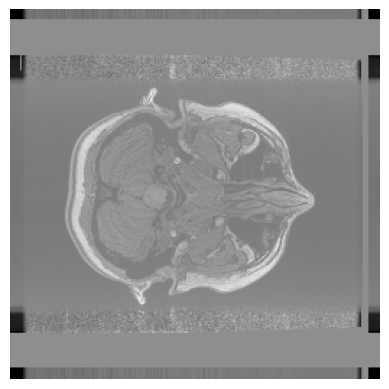

In [26]:
sub_squeeze = subject_tensor.squeeze(0).squeeze(0).to("cpu")

img_slice = sub_squeeze[:,:,50]

plt.imshow(img_slice, cmap="gray")
plt.axis("off")
plt.show

In [ ]:
output = outs[0]
print(f"patchtokens shape: {output['x_norm_patchtokens'].shape}")
print(f"cls token shape: {output['x_norm_clstoken'].shape}")


expected_patches = (subject_shape[2] / 16) * (subject_shape[3] / 16) * (subject_shape[4] / 16)

print(f"subject shape: {subject_shape}, expected_patches: {expected_patches}")

patchtokens shape: torch.Size([1, 3072, 792])
cls token shape: torch.Size([1, 792])
subject shape: torch.Size([1, 1, 256, 256, 192]), expected_patches: 3072.0
